# NB11. Expansión de variables y pruebas de significancia

**Proyecto:** Análisis de patrones espacio-temporales de accidentes de tránsito en El Salvador
**Etapa:** 2, CRISP-DM Fases 3 y 4 (Preparación de datos y Modelado)
**Notebook previo:** NB10, Clustering espacio-temporal
**Semilla:** 42

---

## Qué hace este notebook

El modelo de frecuencia seleccionado en NB07 usa ocho variables: `es_lluviosa`, `es_finde`,
`dia_semana`, `periodo_agostino`, `es_feriado`, `prcp_mensual`, `pct_urbano` y
`poblacion_baja`. Dos hechos documentados en notebooks anteriores indican que ese conjunto
deja información fuera:

1. La grilla de NB03 tiene cuatro franjas horarias por día, pero ninguna variable del
   modelo depende de la hora. Para un distrito y un día dados, el modelo predice el mismo
   valor en la madrugada que en la tarde, aunque NB02 mostró que la tarde concentra varias
   veces más siniestros.
2. NB05 dejó la heterogeneidad territorial como limitación y señaló las fuentes que haría
   falta incorporar: parque vehicular por distrito, infraestructura y movilidad. NB08
   descartó variables espaciales por no contar con polígonos de distrito.

Este notebook construye un conjunto de variables candidatas a partir de fuentes oficiales y
del calendario, mide cuánto aporta cada una con pruebas de significancia sobre un modelo
lineal generalizado y decide cuáles pasan a la matriz de trabajo. No entrena el modelo
final.

## Estructura

| Sección | Contenido |
|---|---|
| 1 | Preparación, integridad de artefactos previos y decisiones declaradas |
| 2 | Construcción de las variables candidatas |
| 3 | Redundancia entre variables territoriales |
| 4 | Pruebas de significancia sobre el modelo de Poisson con exposición |
| 5 | Selección de variables y matriz de trabajo v3 |
| 6 | Resumen y limitaciones |

## Reglas de trabajo

| Regla | Contenido |
|---|---|
| Partición | Train 2022-01-01 a 2024-12-31 / prueba 2025-01-01 a 2026-06-30. No se altera. |
| Selección | Partición interna de NB07: ajuste 2022-2023 / validación 2024. |
| Conjunto de prueba | No se usa en este notebook. |
| Criterios | Se fijan en la Sección 1.3, antes de calcular cualquier resultado. |
| Fuentes | Solo las que carga `src/config.py`. Ninguna ruta se escribe en el notebook. |
| Artefactos previos | No se modifican. La matriz v2 queda intacta y la v3 se guarda aparte. |

## 1. Preparación

### 1.1 Entorno e integridad

Se registran los SHA-256 de los artefactos de los que depende el notebook. En la primera
ejecución se crea la línea base; en las siguientes, cualquier cambio detiene la ejecución.
La misma verificación se repite al cierre (Sección 5.3) para demostrar que el notebook no
alteró nada de lo anterior.

In [1]:
# NB11 - 1.1 Entorno, rutas e integridad de artefactos previos

import hashlib
import json
import sys
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd


def _find_root(marcador: str = "src") -> Path:
    """Sube desde el directorio actual hasta encontrar la raiz del repositorio."""
    actual = Path.cwd().resolve()
    for candidato in [actual, *actual.parents]:
        if (candidato / marcador / "config.py").is_file():
            return candidato
    raise RuntimeError(f"No se encontro {marcador}/config.py desde {actual}")


ROOT = _find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config as cfg  # noqa: E402

SEED = cfg.SEED
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

# clave -> (ruta, imprescindible)
ARTEFACTOS_PREVIOS = {
    "matriz_frecuencia_v2": (cfg.PROCESSED_DIR / "matriz_frecuencia_v2.csv", True),
    "nb05_especificacion": (cfg.RESULTS_DIR / "nb05_especificacion_v2.json", True),
    "nb07_especificacion": (cfg.RESULTS_DIR / "nb07_especificacion.json", True),
    "nb07_metricas": (cfg.RESULTS_DIR / "nb07_metricas.json", True),
    "censo": (cfg.CENSO_FILE, True),
    "censo_bienes": (cfg.CENSO_BIENES_FILE, True),
    "censo_trabajo": (cfg.CENSO_TRABAJO_FILE, True),
    "parque": (cfg.PARQUE_FILE, True),
    "parque_catalogo": (cfg.PARQUE_CATALOGO_FILE, True),
    "fiestas": (cfg.FIESTAS_FILE, True),
    "feriados": (cfg.FERIADOS_FILE, True),
}


def sha256_archivo(ruta: Path, bloque: int = 1 << 20) -> str:
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()


faltantes = [str(r.relative_to(ROOT)) for r, imp in ARTEFACTOS_PREVIOS.values() if imp and not r.is_file()]
if faltantes:
    raise FileNotFoundError("Faltan artefactos imprescindibles:\n  - " + "\n  - ".join(faltantes))

hashes_actuales = {k: sha256_archivo(r) for k, (r, _) in ARTEFACTOS_PREVIOS.items() if r.is_file()}
RUTA_HASHES = cfg.RESULTS_DIR / "nb11_hashes_iniciales.json"
if RUTA_HASHES.is_file():
    base = json.loads(RUTA_HASHES.read_text(encoding="utf-8"))["hashes"]
    alterados = [k for k in base if hashes_actuales.get(k) != base[k]]
    if alterados:
        raise RuntimeError(f"Integridad rota: cambiaron {alterados}")
    estado_integridad = f"verificada ({len(base)} archivos)"
else:
    RUTA_HASHES.write_text(json.dumps({
        "notebook": "NB11_expansion_variables",
        "generado": datetime.now().isoformat(timespec="seconds"),
        "hashes": hashes_actuales,
    }, indent=2), encoding="utf-8")
    estado_integridad = f"línea base creada ({len(hashes_actuales)} archivos)"

ESPEC_NB05 = json.loads(ARTEFACTOS_PREVIOS["nb05_especificacion"][0].read_text(encoding="utf-8"))
ESPEC_NB07 = json.loads(ARTEFACTOS_PREVIOS["nb07_especificacion"][0].read_text(encoding="utf-8"))
FEATURES_BASE = list(ESPEC_NB05["esquema_features"]["features"])
CATEGORICAS_BASE = list(ESPEC_NB05["esquema_features"]["categoricas"])
OFFSET_COL = ESPEC_NB05["esquema_features"]["offset"]
TARGET = ESPEC_NB05["esquema_features"]["target"]

print(f"Raíz del proyecto : {ROOT}")
print(f"Integridad        : {estado_integridad}")
print(f"Variables base    : {FEATURES_BASE}")
print(f"Offset            : {OFFSET_COL}")

Raíz del proyecto : /Users/jpurquilla/Desktop/Trabajo de Grado/Etapa 1/siniestralidad-vial-sv
Integridad        : línea base creada (11 archivos)
Variables base    : ['es_lluviosa', 'es_finde', 'dia_semana', 'periodo_agostino', 'es_feriado', 'prcp_mensual', 'pct_urbano', 'poblacion_baja']
Offset            : log_exposicion_v2


### 1.2 Carga de la matriz v2 y particiones

Se carga la matriz de trabajo de NB05 y se reproducen las particiones de NB07. El conteo
de filas de ajuste y de validación funciona como control cruzado: si no coincide con lo que
declara `nb07_especificacion.json`, la matriz no es la misma y el notebook se detiene.

In [2]:
# NB11 - 1.2 Carga de la matriz v2 y particiones

RUTA_V2 = ARTEFACTOS_PREVIOS["matriz_frecuencia_v2"][0]
matriz = pd.read_csv(RUTA_V2, parse_dates=["fecha"])

COL_DISTRITO, COL_DEPTO, COL_FECHA, COL_FRANJA = "distrito_key", "departamento_key", "fecha", "franja_horaria"
COLS_PROHIBIDAS = ["fallecidos", "lesionados"]   # ex post: nunca predictoras

faltan = [c for c in [COL_DISTRITO, COL_DEPTO, COL_FECHA, COL_FRANJA, TARGET, OFFSET_COL, "split", *FEATURES_BASE]
          if c not in matriz.columns]
if faltan:
    raise RuntimeError(f"Faltan columnas en la matriz v2: {faltan}")


def _rango(texto):
    ini, fin = [p.strip() for p in texto.split(" a ")]
    return pd.Timestamp(ini), pd.Timestamp(fin)


AJUSTE_INI, AJUSTE_FIN = _rango(ESPEC_NB07["particion_interna"]["ajuste"])
VALID_INI, VALID_FIN = _rango(ESPEC_NB07["particion_interna"]["validacion"])
MASK_TRAIN = matriz["split"].astype(str).str.lower().eq("train")
MASK_AJUSTE = MASK_TRAIN & matriz[COL_FECHA].between(AJUSTE_INI, AJUSTE_FIN)
MASK_VALID = MASK_TRAIN & matriz[COL_FECHA].between(VALID_INI, VALID_FIN)
MASK_TEST = ~MASK_TRAIN

n_esperado = matriz[COL_DISTRITO].nunique() * matriz[COL_FECHA].nunique() * matriz[COL_FRANJA].nunique()
assert len(matriz) == n_esperado, "El panel no está balanceado"
assert int(MASK_AJUSTE.sum()) == ESPEC_NB07["particion_interna"]["filas_ajuste"], "Ajuste no coincide con NB07"
assert int(MASK_VALID.sum()) == ESPEC_NB07["particion_interna"]["filas_validacion"], "Validación no coincide con NB07"

print(f"Matriz v2          : {matriz.shape[0]:,} filas x {matriz.shape[1]} columnas")
print(f"Distritos          : {matriz[COL_DISTRITO].nunique()}")
print(f"Ajuste 2022-2023   : {MASK_AJUSTE.sum():,} filas (coincide con NB07)")
print(f"Validación 2024    : {MASK_VALID.sum():,} filas (coincide con NB07)")
print(f"Prueba 2025-2026   : {MASK_TEST.sum():,} filas (no se usa en este notebook)")

Matriz v2          : 676,504 filas x 24 columnas
Distritos          : 103
Ajuste 2022-2023   : 300,760 filas (coincide con NB07)
Validación 2024    : 150,792 filas (coincide con NB07)
Prueba 2025-2026   : 224,952 filas (no se usa en este notebook)


### 1.3 Decisiones declaradas antes de calcular

Las reglas de selección se fijan aquí y se guardan en `nb11_decisiones.json` con su marca
de tiempo, antes de construir una sola variable. Con nueve candidatas y varias pruebas, un
criterio elegido después de ver los resultados permitiría justificar casi cualquier
selección.

| Decisión | Contenido |
|---|---|
| **D1** | Toda decisión se toma con la partición interna (ajuste 2022-2023, validación 2024). El conjunto de prueba no se lee. |
| **D2** | El instrumento de las pruebas es una regresión de Poisson con `log_exposicion_v2` como *offset*, la misma especificación de NB05. Se usa porque sus coeficientes tienen interpretación directa y admite pruebas de razón de verosimilitudes entre modelos anidados. XGBoost no produce valores p. |
| **D3** | Sobredispersión: la matriz tiene más varianza que la que supone Poisson (NB02, NB04). Las razones de verosimilitudes se dividen por la dispersión estimada del modelo base (enfoque cuasi-Poisson) y los errores estándar de los coeficientes se calculan agrupados por distrito. Sin esa corrección los valores p serían demasiado pequeños. |
| **D4** | Cada bloque de variables se prueba contra el modelo base de ocho variables. La interacción franja por fin de semana se prueba contra el modelo base más la franja. Los valores p de todos los bloques se corrigen por comparaciones múltiples con el método de Holm. |
| **D5** | Un bloque se selecciona solo si cumple las dos condiciones: valor p de Holm menor que 0.05 y reducción de la devianza de Poisson en validación 2024 de al menos 0.1%. Con más de 300,000 filas de ajuste, casi cualquier variable resulta significativa; la segunda condición exige además que mejore la predicción fuera de la muestra de ajuste. |
| **D6** | Redundancia: entre las variables territoriales nuevas se calcula el VIF a nivel de distrito (103 filas). Mientras alguna supere 5, se descarta la de mayor VIF. `pct_urbano` forma parte del modelo base y no se descarta. |
| **D7** | Variables del parque vehicular: se asigna a cada mes el corte del mes anterior, el último conocido al inicio del mes. Así ninguna celda usa información posterior a su fecha. Los códigos de la transición territorial de 2024 que no pertenecen al catálogo se excluyen. |
| **D8** | Fiestas patronales: San Salvador se excluye de `es_fiesta_patronal`, porque sus Fiestas Agostinas ya están representadas por `periodo_agostino` y por el feriado local de `es_feriado`. |

In [3]:
# NB11 - 1.3 Registro de decisiones (antes de calcular)

ALFA = 0.05
MEJORA_MINIMA_DEVIANZA = 0.001   # 0.1% de reduccion relativa en validacion
VIF_MAX = 5.0

DECISIONES = {
    "notebook": "NB11_expansion_variables",
    "generado": datetime.now().isoformat(timespec="seconds"),
    "seed": SEED,
    "D1_particion": "Seleccion con ajuste 2022-2023 / validacion 2024. El test no se lee.",
    "D2_instrumento": "Poisson con offset log_exposicion_v2 (especificacion de NB05).",
    "D3_sobredispersion": "LR dividida por la dispersion de Pearson del modelo base; errores estandar agrupados por distrito.",
    "D4_bloques": "Cada bloque contra el modelo base; la interaccion franja x fin de semana contra base + franja. Correccion de Holm.",
    "D5_seleccion": {"alfa_holm": ALFA, "mejora_minima_devianza_validacion": MEJORA_MINIMA_DEVIANZA},
    "D6_redundancia": {"vif_max": VIF_MAX, "nivel": "distrito (103)", "protegida": "pct_urbano"},
    "D7_parque": "Corte del mes anterior; codigos de transicion fuera de catalogo excluidos.",
    "D8_fiestas": "San Salvador excluido (cubierto por periodo_agostino y es_feriado).",
}
cfg.save_metrics(DECISIONES, "nb11_decisiones")
print("Decisiones registradas en reports/results/nb11_decisiones.json")

Decisiones registradas en reports/results/nb11_decisiones.json


## 2. Construcción de las variables candidatas

### 2.1 Franja horaria y quincena

La franja ya existe en la matriz como texto. Se codifica con un orden fijo, de la madrugada
a la noche, para que el código numérico sea el mismo en cualquier ejecución.

`es_quincena` marca los días de pago quincenal (14, 15, 16, 29, 30, 31 y 1 de cada mes).
La hipótesis es que esos días concentran más movilidad y consumo.

Antes de probar nada se describe la variación por franja en la partición de ajuste, para
dimensionar lo que el modelo actual no puede representar.

In [4]:
# NB11 - 2.1 Franja horaria y quincena

ORDEN_FRANJAS = ["Madrugada (00-05)", "Manana (06-11)", "Tarde (12-17)", "Noche (18-23)"]
desconocidas = set(matriz[COL_FRANJA].unique()) - set(ORDEN_FRANJAS)
if desconocidas:
    raise RuntimeError(f"Franjas no previstas en la matriz: {desconocidas}")

matriz["franja_cod"] = pd.Categorical(matriz[COL_FRANJA], categories=ORDEN_FRANJAS).codes.astype(int)
matriz["es_quincena"] = matriz[COL_FECHA].dt.day.isin([1, 14, 15, 16, 29, 30, 31]).astype(int)

desc = (matriz[MASK_AJUSTE]
        .groupby(COL_FRANJA, observed=True)[TARGET]
        .agg(celdas="size", siniestros="sum", media="mean")
        .reindex(ORDEN_FRANJAS))
desc["pct_siniestros"] = 100 * desc["siniestros"] / desc["siniestros"].sum()
desc["razon_vs_madrugada"] = desc["media"] / desc.loc["Madrugada (00-05)", "media"]
print("Siniestros por franja, ajuste 2022-2023")
display(desc.round(4))

q = matriz[MASK_AJUSTE].groupby("es_quincena")[TARGET].mean()
print(f"\nMedia por celda: días de quincena {q.get(1, np.nan):.5f} | resto {q.get(0, np.nan):.5f}")

Siniestros por franja, ajuste 2022-2023


,celdas,siniestros,media,pct_siniestros,razon_vs_madrugada
franja_horaria,,,,,
Madrugada (00-05),75190,2662,0.0354,7.4210,1.0000
Manana (06-11),75190,10583,0.1408,29.5029,3.9756
Tarde (12-17),75190,13180,0.1753,36.7428,4.9512
Noche (18-23),75190,9446,0.1256,26.3332,3.5485



Media por celda: días de quincena 0.11939 | resto 0.11924


### 2.2 Fiestas patronales

El calendario de fiestas (`cfg.load_fiestas()`) tiene una fila por distrito y día de fiesta
entre 2022 y 2026. Se une a la matriz con las mismas claves de NB03
(`reconciliar_distrito` para el distrito y `norm_distrito` para el departamento).

In [5]:
# NB11 - 2.2 Fiestas patronales

fiestas = cfg.load_fiestas()
fiestas["distrito_key"] = fiestas["distrito"].map(cfg.reconciliar_distrito)
fiestas["departamento_key"] = fiestas["departamento"].map(cfg.norm_distrito)
fiestas["fecha"] = pd.to_datetime(fiestas["fecha"])

# D8: San Salvador queda fuera
fiestas = fiestas[~((fiestas["departamento_key"] == "san salvador") & (fiestas["distrito_key"] == "san salvador"))]

dias_fiesta = fiestas[["departamento_key", "distrito_key", "fecha"]].drop_duplicates().assign(es_fiesta_patronal=1)
matriz = matriz.merge(dias_fiesta, on=["departamento_key", "distrito_key", "fecha"], how="left")
matriz["es_fiesta_patronal"] = matriz["es_fiesta_patronal"].fillna(0).astype(int)

claves_matriz = set(zip(matriz[COL_DEPTO], matriz[COL_DISTRITO]))
claves_fiesta = set(zip(fiestas["departamento_key"], fiestas["distrito_key"]))
sin_fiesta = sorted(claves_matriz - claves_fiesta)

print(f"Distritos de la matriz con fiestas en el calendario: {len(claves_matriz) - len(sin_fiesta)} de {len(claves_matriz)}")
print(f"Sin fiesta asignada: {sin_fiesta}")
print(f"Celdas en fiesta: {matriz['es_fiesta_patronal'].mean():.2%}")
f = matriz[MASK_AJUSTE].groupby("es_fiesta_patronal")[TARGET].mean()
print(f"Media por celda en ajuste: en fiesta {f.get(1, np.nan):.5f} | resto {f.get(0, np.nan):.5f}")

Distritos de la matriz con fiestas en el calendario: 102 de 103
Sin fiesta asignada: [('san salvador', 'san salvador')]
Celdas en fiesta: 1.48%
Media por celda en ajuste: en fiesta 0.14430 | resto 0.11888


### 2.3 Parque vehicular

El parque del Registro Público de Vehículos viene por corte mensual y por código de
distrito del registro (antiguos municipios). El cruce con las claves de la matriz se hace
por nombre dentro de cada departamento. El registro abrevia muchos nombres («SAN FCO
GOTERA», «STGO D LA FRONT»), así que primero se expanden las abreviaturas y, si no hay
coincidencia exacta, se toma la más parecida. Todos los cruces que no son exactos se
imprimen para revisarlos.

Se construyen dos variables por distrito y mes, ambas con el corte del mes anterior (D7):

- `pct_motocicletas`: proporción de motocicletas en el parque inscrito.
- `crec_parque_12m`: crecimiento del parque en los doce meses previos. Recoge la hipótesis
  de NB08 de que los distritos rurales crecen a otro ritmo.

In [6]:
# NB11 - 2.3 Parque vehicular: cruce de codigos y variables mensuales

import difflib

parque = cfg.load_parque_vehicular()
catalogo = cfg.load_parque_catalogo()

ABREV = {"sn": "san", "sta": "santa", "fco": "francisco", "j": "jose", "sto": "santo", "cdad": "ciudad",
         "nva": "nueva", "pto": "puerto", "conc": "concepcion", "stgo": "santiago", "d": "de", "front": "frontera"}
CRUCE_MANUAL = {("santa ana", "santiago de la frontera"): 212}


def _expandir(nombre):
    return " ".join(ABREV.get(p, p) for p in cfg.norm_distrito(nombre).split())


catalogo["dep"] = catalogo["departamento"].map(cfg.norm_distrito)
catalogo["nom"] = catalogo["distrito"].map(_expandir)

cruce = []
for dep, dis in sorted(claves_matriz):
    if (dep, dis) in CRUCE_MANUAL:
        cruce.append((dep, dis, CRUCE_MANUAL[(dep, dis)], "manual")); continue
    sub = catalogo[catalogo["dep"] == dep]
    exacto = sub[sub["nom"] == dis]
    if len(exacto) == 1:
        cruce.append((dep, dis, int(exacto["cod_distrito"].iloc[0]), "exacto")); continue
    parecido = difflib.get_close_matches(dis, sub["nom"].tolist(), n=1, cutoff=0.55)
    if not parecido:
        raise RuntimeError(f"Sin cruce para {dep} / {dis}")
    cruce.append((dep, dis, int(sub.loc[sub["nom"] == parecido[0], "cod_distrito"].iloc[0]), "aproximado"))

cruce = pd.DataFrame(cruce, columns=["departamento_key", "distrito_key", "cod_distrito", "tipo"])
assert not cruce["cod_distrito"].duplicated().any(), "Dos distritos apuntan al mismo código del registro"
print(f"Cruce: {cruce['tipo'].value_counts().to_dict()}")
revisar = cruce[cruce["tipo"] != "exacto"].merge(catalogo[["cod_distrito", "distrito"]], on="cod_distrito")
display(revisar.rename(columns={"distrito": "nombre_en_registro"}))

# Parque mensual por codigo (los codigos fuera del catalogo se excluyen, D7)
p = parque[parque["cod_distrito"].isin(catalogo["cod_distrito"])].copy()
p["grupo"] = np.where(p["cod_clase"] == 309, "motos", "otros")
mensual = p.pivot_table(index=["cod_distrito", "fecha_ref"], columns="grupo", values="vehiculos",
                        aggfunc="sum", fill_value=0).reset_index()
mensual["total"] = mensual["motos"] + mensual["otros"]
mensual["pct_motocicletas"] = mensual["motos"] / mensual["total"]
mensual = mensual.sort_values(["cod_distrito", "fecha_ref"])
mensual["periodo"] = mensual["fecha_ref"].dt.to_period("M")
total_12m_antes = mensual.set_index(["cod_distrito", "periodo"])["total"]
mensual["total_12m_antes"] = [total_12m_antes.get((c, per - 12), np.nan)
                              for c, per in zip(mensual["cod_distrito"], mensual["periodo"])]
mensual["crec_parque_12m"] = mensual["total"] / mensual["total_12m_antes"] - 1

# D7: el mes t usa el corte del mes t-1
mensual["periodo_uso"] = mensual["periodo"] + 1
var_parque = mensual[["cod_distrito", "periodo_uso", "pct_motocicletas", "crec_parque_12m"]]

matriz["periodo_uso"] = matriz[COL_FECHA].dt.to_period("M")
matriz = (matriz.merge(cruce[["departamento_key", "distrito_key", "cod_distrito"]], on=["departamento_key", "distrito_key"], how="left")
                .merge(var_parque, on=["cod_distrito", "periodo_uso"], how="left"))

nulos = matriz[["pct_motocicletas", "crec_parque_12m"]].isna().sum()
assert nulos.sum() == 0, f"Celdas sin dato de parque: {nulos.to_dict()}"
print("\nVariables de parque asignadas a todas las celdas (corte del mes anterior).")
print(matriz.groupby(COL_DISTRITO)[["pct_motocicletas", "crec_parque_12m"]].mean().describe().round(4))

Cruce: {'exacto': 96, 'aproximado': 7}


,departamento_key,distrito_key,cod_distrito,tipo,nombre_en_registro
0,cuscatlan,san pedro perulapan,710,aproximado,SAN P PERULAPAN
1,cuscatlan,san rafael cedros,711,aproximado,SAN RAF CEDROS
2,la libertad,antiguo cuscatlan,501,aproximado,ANTGO CUSCATLAN
3,la paz,san juan nonualco,810,aproximado,SAN J NONUALCO
4,la union,santa rosa de lima,1416,aproximado,SANTA ROSA LIMA
5,san miguel,san rafael oriente,1218,aproximado,SAN RAF ORIENTE
6,usulutan,concepcion batres,1104,aproximado,CONCEP BATRES



Variables de parque asignadas a todas las celdas (corte del mes anterior).
       pct_motocicletas  crec_parque_12m
count          103.0000         103.0000
mean             0.3736           0.1051
std              0.1029           0.0283
min              0.1281           0.0122
25%              0.2849           0.0885
50%              0.3780           0.1079
75%              0.4378           0.1216
max              0.6676           0.1849


### 2.4 Censo 2024: vehículos en el hogar y lugar de trabajo

Del Censo 2024 se toman tres proporciones por distrito, constantes en el tiempo:

- `pct_hogares_moto` y `pct_hogares_auto`: hogares que disponen de motocicleta o automóvil.
  Miden la exposición vehicular por lugar de residencia, a diferencia del registro, que la
  asigna por domicilio del propietario.
- `pct_trabaja_otro_lugar`: proporción de ocupados que trabajan fuera de su localidad de
  residencia. Es la aproximación disponible a la movilidad pendular que NB04 y NB05 asociaron
  con el error en el Área Metropolitana.

`pct_urbano` ya proviene de este mismo censo (`load_censo`) y no se duplica.

In [7]:
# NB11 - 2.4 Variables del censo 2024

bienes = cfg.load_censo_bienes()
trabajo = cfg.load_censo_trabajo()
for t in (bienes, trabajo):
    t["distrito_key"] = t["distrito"].map(cfg.reconciliar_distrito)
    t["departamento_key"] = t["departamento"].map(cfg.norm_distrito)

bienes["pct_hogares_moto"] = bienes["motocicleta_si"] / bienes["hogares"]
bienes["pct_hogares_auto"] = bienes["automovil_si"] / bienes["hogares"]
trabajo["pct_trabaja_otro_lugar"] = trabajo["otro_lugar"] / trabajo["ocupados"]

censo_nuevo = (bienes[["departamento_key", "distrito_key", "pct_hogares_moto", "pct_hogares_auto"]]
               .merge(trabajo[["departamento_key", "distrito_key", "pct_trabaja_otro_lugar"]],
                      on=["departamento_key", "distrito_key"]))
matriz = matriz.merge(censo_nuevo, on=["departamento_key", "distrito_key"], how="left")

nulos = matriz[["pct_hogares_moto", "pct_hogares_auto", "pct_trabaja_otro_lugar"]].isna().sum()
assert nulos.sum() == 0, f"Distritos sin dato censal: {nulos.to_dict()}"
print("Variables censales asignadas a los 103 distritos.")
print(matriz.groupby(COL_DISTRITO)[["pct_hogares_moto", "pct_hogares_auto", "pct_trabaja_otro_lugar"]]
      .first().describe().round(4))

Variables censales asignadas a los 103 distritos.
       pct_hogares_moto  pct_hogares_auto  pct_trabaja_otro_lugar
count          103.0000          103.0000                103.0000
mean             0.1890            0.2558                  0.2739
std              0.0619            0.0941                  0.1747
min              0.0629            0.0678                  0.0180
25%              0.1383            0.2049                  0.1258
50%              0.1912            0.2444                  0.2435
75%              0.2352            0.2907                  0.4305
max              0.3438            0.7184                  0.6056


### 2.5 Resumen de las candidatas

In [8]:
# NB11 - 2.5 Resumen de las variables candidatas

CANDIDATAS = {
    "franja_cod": ("temporal", "franja horaria", "siniestros.csv (grilla de NB03)"),
    "es_quincena": ("temporal", "día", "calendario"),
    "es_fiesta_patronal": ("temporal y territorial", "distrito y día", "calendario de fiestas patronales"),
    "pct_motocicletas": ("territorial", "distrito y mes", "ONASEVI, Registro Público de Vehículos"),
    "crec_parque_12m": ("territorial", "distrito y mes", "ONASEVI, Registro Público de Vehículos"),
    "pct_hogares_moto": ("territorial", "distrito", "Censo 2024, TAB_HOG_4"),
    "pct_hogares_auto": ("territorial", "distrito", "Censo 2024, TAB_HOG_4"),
    "pct_trabaja_otro_lugar": ("territorial", "distrito", "Censo 2024, TAB_CE_5"),
}
resumen = pd.DataFrame([
    {"variable": v, "tipo": t, "resolucion": r, "fuente": f,
     "nulos": int(matriz[v].isna().sum()), "media_ajuste": float(matriz.loc[MASK_AJUSTE, v].mean())}
    for v, (t, r, f) in CANDIDATAS.items()
])
display(resumen.round(4))

,variable,tipo,resolucion,fuente,nulos,media_ajuste
0,franja_cod,temporal,franja horaria,siniestros.csv (grilla de NB03),0,1.5000
1,es_quincena,temporal,día,calendario,0,0.2110
2,es_fiesta_patronal,temporal y territorial,distrito y día,calendario de fiestas patronales,0,0.0152
3,pct_motocicletas,territorial,distrito y mes,"ONASEVI, Registro Público de Vehículos",0,0.3597
4,crec_parque_12m,territorial,distrito y mes,"ONASEVI, Registro Público de Vehículos",0,0.1144
5,pct_hogares_moto,territorial,distrito,"Censo 2024, TAB_HOG_4",0,0.1890
6,pct_hogares_auto,territorial,distrito,"Censo 2024, TAB_HOG_4",0,0.2558
7,pct_trabaja_otro_lugar,territorial,distrito,"Censo 2024, TAB_CE_5",0,0.2739


## 3. Redundancia entre variables territoriales

Las variables territoriales son constantes, o casi, dentro de cada distrito, así que su
redundancia se mide con una fila por distrito. Se calcula la correlación de Spearman y el
factor de inflación de la varianza (VIF), y se aplica la regla D6.

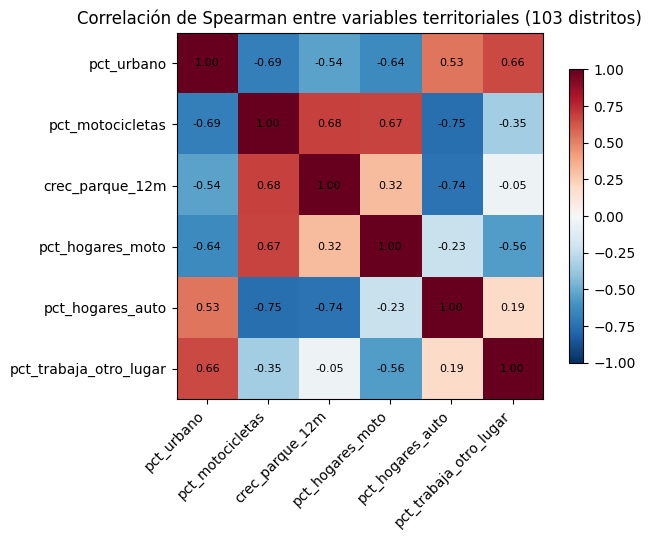

Se descarta pct_motocicletas (VIF 5.91 > 5.0)

VIF final:


,VIF
pct_urbano,2.391
crec_parque_12m,2.933
pct_hogares_moto,1.745
pct_hogares_auto,2.585
pct_trabaja_otro_lugar,2.014


Territoriales que pasan a las pruebas: ['crec_parque_12m', 'pct_hogares_moto', 'pct_hogares_auto', 'pct_trabaja_otro_lugar']
Descartadas por redundancia: ['pct_motocicletas']


In [9]:
# NB11 - 3.1 Correlaciones y VIF a nivel de distrito

import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

TERRITORIALES_NUEVAS = ["pct_motocicletas", "crec_parque_12m", "pct_hogares_moto", "pct_hogares_auto", "pct_trabaja_otro_lugar"]
por_distrito = matriz[MASK_AJUSTE].groupby(COL_DISTRITO)[["pct_urbano", *TERRITORIALES_NUEVAS]].mean()

corr = por_distrito.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación de Spearman entre variables territoriales (103 distritos)")
fig.tight_layout()
cfg.save_fig(fig, "nb11_01_correlaciones_territoriales")
plt.show()


def tabla_vif(df):
    z = (df - df.mean()) / df.std()
    X = sm.add_constant(z)
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=df.columns)


conservadas = list(TERRITORIALES_NUEVAS)
historial_vif = []
while True:
    vif = tabla_vif(por_distrito[["pct_urbano", *conservadas]])
    historial_vif.append(vif.round(3).to_dict())
    candidatas_a_salir = vif.drop("pct_urbano")
    if candidatas_a_salir.max() <= VIF_MAX:
        break
    sale = candidatas_a_salir.idxmax()
    print(f"Se descarta {sale} (VIF {candidatas_a_salir.max():.2f} > {VIF_MAX})")
    conservadas.remove(sale)

print("\nVIF final:")
display(vif.round(3).to_frame("VIF"))
DESCARTADAS_VIF = [v for v in TERRITORIALES_NUEVAS if v not in conservadas]
print(f"Territoriales que pasan a las pruebas: {conservadas}")
print(f"Descartadas por redundancia: {DESCARTADAS_VIF or 'ninguna'}")

## 4. Pruebas de significancia

### 4.1 Modelo base e instrumento

El modelo base es la regresión de Poisson de NB05: las ocho variables, `dia_semana` como
categórica y `log_exposicion_v2` como *offset*. Se ajusta sobre 2022-2023.

Para cada bloque se ajusta el modelo ampliado y se calculan:

- **Razón de verosimilitudes corregida** (D3): `LR / φ`, donde φ es la dispersión de
  Pearson del modelo base. Bajo la hipótesis de que el bloque no aporta, se distribuye
  aproximadamente como chi cuadrado con tantos grados de libertad como coeficientes agrega.
- **Mejora en validación**: reducción relativa de la devianza de Poisson en 2024, con el
  modelo ajustado en 2022-2023.

`es_finde` se deriva de `dia_semana` (viernes y sábado), igual que en la especificación de
NB05, así que las dos no se pueden separar en un modelo lineal. Se conserva la
especificación de NB05 para que el modelo base sea el mismo; el coeficiente de `es_finde`
no se interpreta por separado y su error estándar puede aparecer vacío en la Sección 4.3.

In [10]:
# NB11 - 4.1 Funciones del modelo de Poisson con exposicion

from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import SingularMatrixWarning

# es_finde se deriva de dia_semana (viernes y sabado), igual que en NB05: la matriz de diseno
# es de rango incompleto y statsmodels lo resuelve con seudoinversa. El aviso se silencia.
warnings.filterwarnings("ignore", category=SingularMatrixWarning)

ajuste = matriz[MASK_AJUSTE].reset_index(drop=True)
valida = matriz[MASK_VALID].reset_index(drop=True)

BLOQUES = {
    "franja": ["franja_cod"],
    "quincena": ["es_quincena"],
    "fiesta_patronal": ["es_fiesta_patronal"],
    **{v: [v] for v in conservadas},
}
CATEGORICAS = [*CATEGORICAS_BASE, "franja_cod"]


def diseno(df, columnas, interaccion=False, ref=None):
    X = df[columnas].copy()
    X = pd.get_dummies(X, columns=[c for c in CATEGORICAS if c in columnas], drop_first=True, dtype=float)
    if interaccion:
        for k in (1, 2, 3):
            X[f"franja_{k}_x_finde"] = (df["franja_cod"] == k).astype(float) * df["es_finde"]
    X = sm.add_constant(X.astype(float), has_constant="add")
    if ref is not None:
        X = X.reindex(columns=ref, fill_value=0.0)
    return X


def ajustar(columnas, interaccion=False):
    X = diseno(ajuste, columnas, interaccion)
    res = sm.GLM(ajuste[TARGET], X, family=sm.families.Poisson(), offset=ajuste[OFFSET_COL]).fit()
    return res, list(X.columns)


def devianza_validacion(res, columnas, ref, interaccion=False):
    mu = res.predict(diseno(valida, columnas, interaccion, ref), offset=valida[OFFSET_COL])
    y = valida[TARGET].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        termino = np.where(y > 0, y * np.log(y / mu), 0.0)
    return float(2 * np.sum(termino - (y - mu))), mu


base, ref_base = ajustar(FEATURES_BASE)
PHI = float(base.pearson_chi2 / base.df_resid)
dev_val_base, mu_base = devianza_validacion(base, FEATURES_BASE, ref_base)
print(f"Modelo base: {len(ref_base)} coeficientes | log-verosimilitud {base.llf:,.1f}")
print(f"Dispersión de Pearson φ = {PHI:.4f}")
print(f"Devianza en validación 2024: {dev_val_base:,.1f}")

Modelo base: 14 coeficientes | log-verosimilitud -93,594.1
Dispersión de Pearson φ = 1.0075
Devianza en validación 2024: 69,161.7


### 4.2 Prueba de cada bloque

In [11]:
# NB11 - 4.2 Razon de verosimilitudes corregida y mejora en validacion por bloque

filas = []
modelo_franja = None
for nombre, columnas in BLOQUES.items():
    cols = [*FEATURES_BASE, *columnas]
    res, ref = ajustar(cols)
    lr = 2 * (res.llf - base.llf) / PHI
    gl = len(ref) - len(ref_base)
    dev, _ = devianza_validacion(res, cols, ref)
    filas.append({"bloque": nombre, "gl": gl, "LR_corregida": lr, "p": stats.chi2.sf(lr, gl),
                  "devianza_validacion": dev, "mejora_validacion": (dev_val_base - dev) / dev_val_base})
    if nombre == "franja":
        modelo_franja, ref_franja = res, ref

# interaccion franja x fin de semana, contra base + franja
cols_f = [*FEATURES_BASE, "franja_cod"]
res_i, ref_i = ajustar(cols_f, interaccion=True)
dev_f, _ = devianza_validacion(modelo_franja, cols_f, ref_franja)
dev_i, _ = devianza_validacion(res_i, cols_f, ref_i, interaccion=True)
lr_i = 2 * (res_i.llf - modelo_franja.llf) / PHI
filas.append({"bloque": "franja_x_finde", "gl": len(ref_i) - len(ref_franja), "LR_corregida": lr_i,
              "p": stats.chi2.sf(lr_i, len(ref_i) - len(ref_franja)), "devianza_validacion": dev_i,
              "mejora_validacion": (dev_f - dev_i) / dev_f})

pruebas = pd.DataFrame(filas)
pruebas["p_holm"] = multipletests(pruebas["p"], method="holm")[1]
pruebas["significativo"] = pruebas["p_holm"] < ALFA
pruebas["mejora_suficiente"] = pruebas["mejora_validacion"] >= MEJORA_MINIMA_DEVIANZA
pruebas["seleccionado"] = pruebas["significativo"] & pruebas["mejora_suficiente"]

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
display(pruebas)

,bloque,gl,LR_corregida,p,devianza_validacion,mejora_validacion,p_holm,significativo,mejora_suficiente,seleccionado
0,franja,3,"8,110.52",0,"64,501.4",0.0673827,0,True,True,True
1,quincena,1,0.00278453,0.957916,"69,161.5",2.33039e-06,1,False,False,False
2,fiesta_patronal,1,7.11278,0.00765365,"69,155.6",8.77306e-05,0.0229609,True,False,False
3,crec_parque_12m,1,"1,628.26",0,"68,669.9",0.0071106,0,True,True,True
4,pct_hogares_moto,1,135.625,2.41039e-31,"69,231",-0.00100263,9.64155e-31,True,False,False
5,pct_hogares_auto,1,"3,338.34",0,"67,141",0.029216,0,True,True,True
6,pct_trabaja_otro_lugar,1,"1,602.38",0,"67,641.2",0.0219842,0,True,True,True
7,franja_x_finde,3,1.7222,0.632009,"64,500.9",7.40453e-06,1,False,False,False


### 4.3 Modelo con los bloques seleccionados

Se ajusta un modelo con todos los bloques que cumplen D5 y se reportan sus coeficientes como
razones de tasas (`exp(β)`), con intervalos de confianza de 95% y errores estándar
agrupados por distrito. Una razón de 1.20 significa un 20% más de siniestros esperados por
unidad de exposición, con el resto de variables constante.

Se compara además la calibración por franja del modelo base y del modelo con los bloques
seleccionados en validación 2024. Es la consecuencia práctica de que el modelo base no
tenga ninguna variable horaria.

Bloques seleccionados: ['franja', 'crec_parque_12m', 'pct_hogares_auto', 'pct_trabaja_otro_lugar']


/Users/jpurquilla/Desktop/Trabajo de Grado/Etapa 1/siniestralidad-vial-sv/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


,razon_tasas,ic95_inf,ic95_sup,z,p
es_lluviosa,0.9436,0.8894,1.0012,-1.9203,0.0548
es_finde,1.0335,NaN,NaN,NaN,NaN
periodo_agostino,1.3588,1.2409,1.4878,6.6226,0
es_feriado,1.145,1.0729,1.222,4.08,0
prcp_mensual,1.0009,1.0006,1.0012,6.2291,0
pct_urbano,2.2636,1.4311,3.5806,3.492,0.0005
poblacion_baja,1.1004,0.7112,1.7024,0.4295,0.6675
crec_parque_12m,23.4145,2.0849,262.962,2.5553,0.0106
pct_hogares_auto,25.3597,9.176,70.0865,6.2336,0
pct_trabaja_otro_lugar,0.4131,0.2466,0.6921,-3.3573,0.0008



Calibración por franja en validación 2024 (predicho / observado)


,calibracion_base,calibracion_seleccionado
franja,,
Madrugada (00-05),3.5081,1.0039
Manana (06-11),0.8923,1.0152
Tarde (12-17),0.704,0.9976
Noche (18-23),1.0142,1.0299


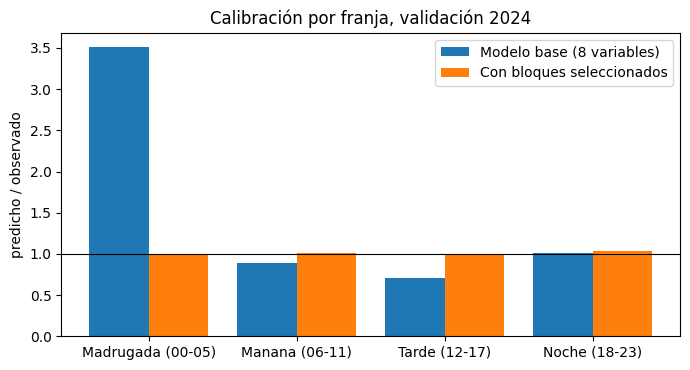


Devianza en validación: base 69,161.7 | seleccionado 61,667.1 (10.84% menos)


In [12]:
# NB11 - 4.3 Modelo con bloques seleccionados: razones de tasas y calibracion por franja

SELECCIONADOS = pruebas.loc[pruebas["seleccionado"], "bloque"].tolist()
con_interaccion = "franja_x_finde" in SELECCIONADOS
cols_sel = [*FEATURES_BASE, *[c for b in SELECCIONADOS if b != "franja_x_finde" for c in BLOQUES[b]]]
if con_interaccion and "franja_cod" not in cols_sel:
    cols_sel.append("franja_cod")

X_sel = diseno(ajuste, cols_sel, con_interaccion)
final = sm.GLM(ajuste[TARGET], X_sel, family=sm.families.Poisson(), offset=ajuste[OFFSET_COL]).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(ajuste[COL_DISTRITO])[0]})
tabla = pd.DataFrame({
    "razon_tasas": np.exp(final.params),
    "ic95_inf": np.exp(final.conf_int()[0]),
    "ic95_sup": np.exp(final.conf_int()[1]),
    "z": final.tvalues,
    "p": final.pvalues,
}).drop(index="const")
print(f"Bloques seleccionados: {SELECCIONADOS or 'ninguno'}")
display(tabla.round(4))

dev_sel, mu_sel = devianza_validacion(final, cols_sel, list(X_sel.columns), con_interaccion)
cal = (pd.DataFrame({"franja": valida[COL_FRANJA], "obs": valida[TARGET], "base": mu_base, "seleccionado": mu_sel})
       .groupby("franja").sum().reindex(ORDEN_FRANJAS))
cal["calibracion_base"] = cal["base"] / cal["obs"]
cal["calibracion_seleccionado"] = cal["seleccionado"] / cal["obs"]
print("\nCalibración por franja en validación 2024 (predicho / observado)")
display(cal[["calibracion_base", "calibracion_seleccionado"]].round(4))

fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(ORDEN_FRANJAS))
ax.bar(x - 0.2, cal["calibracion_base"], 0.4, label="Modelo base (8 variables)")
ax.bar(x + 0.2, cal["calibracion_seleccionado"], 0.4, label="Con bloques seleccionados")
ax.axhline(1, color="black", lw=0.8)
ax.set_xticks(x, ORDEN_FRANJAS)
ax.set_ylabel("predicho / observado")
ax.set_title("Calibración por franja, validación 2024")
ax.legend()
fig.tight_layout()
cfg.save_fig(fig, "nb11_02_calibracion_por_franja")
plt.show()
print(f"\nDevianza en validación: base {dev_val_base:,.1f} | seleccionado {dev_sel:,.1f} "
      f"({(dev_val_base - dev_sel) / dev_val_base:.2%} menos)")

## 5. Matriz de trabajo v3

### 5.1 Matriz y especificación

La matriz v3 es la v2 con las columnas candidatas añadidas, se hayan seleccionado o no. Se
guarda comprimida (`matriz_frecuencia_v3.csv.gz`) porque sin comprimir supera los 170 MB;
`pandas` la lee igual que un CSV.
Así cualquier verificación posterior puede repetirse sin reconstruirlas. Lo que define qué
usa el modelo es `nb11_especificacion.json`.

In [13]:
# NB11 - 5.1 Guardado de la matriz v3 y de la especificacion

RUTA_V3 = cfg.PROCESSED_DIR / "matriz_frecuencia_v3.csv.gz"   # comprimida: sin comprimir supera 170 MB
if RUTA_V3.exists():
    raise FileExistsError(f"{RUTA_V3.name} ya existe. Borrarlo a mano si se quiere regenerar.")

columnas_v2 = pd.read_csv(RUTA_V2, nrows=0).columns.tolist()
nuevas = ["franja_cod", *CANDIDATAS.keys() - {"franja_cod"}]
v3 = matriz[columnas_v2 + [c for c in nuevas if c not in columnas_v2]].sort_values([COL_DISTRITO, COL_FECHA, COL_FRANJA])
assert len(v3) == len(matriz) and v3[nuevas].notna().all().all()
v3.to_csv(RUTA_V3, index=False, compression="gzip")

features_v3 = [*FEATURES_BASE, *[c for b in SELECCIONADOS if b != "franja_x_finde" for c in BLOQUES[b]]]
if con_interaccion and "franja_cod" not in features_v3:
    features_v3.append("franja_cod")

ESPEC = {
    "notebook": "NB11_expansion_variables",
    "generado": datetime.now().isoformat(timespec="seconds"),
    "matriz": RUTA_V3.name,
    "target": TARGET,
    "offset": OFFSET_COL,
    "features": features_v3,
    "categoricas": [c for c in CATEGORICAS if c in features_v3],
    "codificacion_franja": {k: v for v, k in enumerate(ORDEN_FRANJAS)},
    "interaccion_franja_finde": bool(con_interaccion),
    "candidatas": {k: {"tipo": t, "resolucion": r, "fuente": f} for k, (t, r, f) in CANDIDATAS.items()},
    "split": ESPEC_NB07["split"],
    "particion_interna": ESPEC_NB07["particion_interna"],
}
cfg.save_metrics(ESPEC, "nb11_especificacion")
cfg.save_metrics({
    "notebook": "NB11_expansion_variables",
    "dispersion_pearson_base": PHI,
    "devianza_validacion_base": dev_val_base,
    "devianza_validacion_seleccionado": dev_sel,
    "vif": historial_vif,
    "descartadas_vif": DESCARTADAS_VIF,
    "pruebas": pruebas.to_dict(orient="records"),
    "seleccionados": SELECCIONADOS,
    "razones_tasas": tabla.reset_index(names="variable").to_dict(orient="records"),
    "calibracion_por_franja_validacion": cal[["calibracion_base", "calibracion_seleccionado"]].reset_index().to_dict(orient="records"),
}, "nb11_metricas")
print(f"Matriz v3: {RUTA_V3.relative_to(ROOT)} ({RUTA_V3.stat().st_size / 1024**2:.1f} MB)")
print(f"Variables del modelo: {features_v3}")

Matriz v3: data/processed/matriz_frecuencia_v3.csv.gz (3.8 MB)
Variables del modelo: ['es_lluviosa', 'es_finde', 'dia_semana', 'periodo_agostino', 'es_feriado', 'prcp_mensual', 'pct_urbano', 'poblacion_baja', 'franja_cod', 'crec_parque_12m', 'pct_hogares_auto', 'pct_trabaja_otro_lugar']


### 5.2 Verificación de cierre

Se recalculan los SHA-256 de los artefactos previos. Si alguno cambió durante la ejecución,
el notebook lo informa como error.

In [14]:
# NB11 - 5.2 Integridad al cierre

cambios = [k for k, (r, _) in ARTEFACTOS_PREVIOS.items() if r.is_file() and sha256_archivo(r) != hashes_actuales[k]]
if cambios:
    raise RuntimeError(f"El notebook modificó artefactos previos: {cambios}")
print(f"Integridad de artefactos previos: verificada ({len(hashes_actuales)} archivos intactos)")

Integridad de artefactos previos: verificada (11 archivos intactos)


## 6. Resumen y limitaciones

In [15]:
# NB11 - 6.1 Resumen de resultados

print("PRUEBAS POR BLOQUE (ajuste 2022-2023, validación 2024)")
print("-" * 78)
for r in pruebas.itertuples():
    estado = "SELECCIONADO" if r.seleccionado else ("significativo, sin mejora suficiente" if r.significativo else "no significativo")
    print(f"  {r.bloque:<24} LR={r.LR_corregida:>10.1f} gl={r.gl}  p_Holm={r.p_holm:.2e}  "
          f"mejora val.={r.mejora_validacion:>7.3%}  -> {estado}")
print("-" * 78)
print(f"Descartadas por redundancia (VIF > {VIF_MAX}): {DESCARTADAS_VIF or 'ninguna'}")
print(f"Variables del modelo v3: {features_v3}")

PRUEBAS POR BLOQUE (ajuste 2022-2023, validación 2024)
------------------------------------------------------------------------------
  franja                   LR=    8110.5 gl=3  p_Holm=0.00e+00  mejora val.= 6.738%  -> SELECCIONADO
  quincena                 LR=       0.0 gl=1  p_Holm=1.00e+00  mejora val.= 0.000%  -> no significativo
  fiesta_patronal          LR=       7.1 gl=1  p_Holm=2.30e-02  mejora val.= 0.009%  -> significativo, sin mejora suficiente
  crec_parque_12m          LR=    1628.3 gl=1  p_Holm=0.00e+00  mejora val.= 0.711%  -> SELECCIONADO
  pct_hogares_moto         LR=     135.6 gl=1  p_Holm=9.64e-31  mejora val.=-0.100%  -> significativo, sin mejora suficiente
  pct_hogares_auto         LR=    3338.3 gl=1  p_Holm=0.00e+00  mejora val.= 2.922%  -> SELECCIONADO
  pct_trabaja_otro_lugar   LR=    1602.4 gl=1  p_Holm=0.00e+00  mejora val.= 2.198%  -> SELECCIONADO
  franja_x_finde           LR=       1.7 gl=3  p_Holm=1.00e+00  mejora val.= 0.001%  -> no significativo
--

**Limitaciones de este análisis.**

| Limitación | Implicación |
|---|---|
| La capa de eventos es sintética y está calibrada sobre agregados de ONASEVI/FONAT (NB01) | Las variables nuevas son reales, pero el conteo que deben explicar no lo es. Una variable externa puede no mostrar efecto porque el generador no la usó, aunque en la realidad sí influya. La significancia medida aquí describe al conjunto de datos, no a la siniestralidad salvadoreña. |
| El instrumento es lineal en escala logarítmica | Las pruebas miden aporte bajo esa forma funcional. Un efecto no lineal podría pasar inadvertido aquí y aparecer en un modelo de árboles. |
| Variables censales estáticas (corte de mayo-junio de 2024) | Se asignan igual a todo el período 2022-2026. |
| El registro vehicular asigna cada vehículo al domicilio del propietario | `pct_motocicletas` describe dónde están inscritos los vehículos, no dónde circulan. |
| Fechas de fiestas tradicionales | El calendario usa fechas tradicionales por distrito; algunas celebraciones varían de un año a otro y algunos distritos tienen una segunda celebración que no se registra. |
| Holm controla el error de la familia de bloques probados aquí | No corrige por análisis hechos en notebooks anteriores sobre los mismos datos. |